<a href="https://colab.research.google.com/github/indriylstt/cardiovascular_classification_pcg/blob/main/15_8_(default).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.preprocessing import LabelEncoder

In [ ]:
# load dataset
from google.colab import drive
drive.mount('/content/drive')

path_based = '/content/drive/MyDrive/circor_pcg_datasets'

# directory classes
data_dir = Path(path_based)
class_names = sorted(os.listdir(data_dir))
print("Classes:", class_names)

# train directory
train_dir = ['training-a', 'training-b', 'training-c', 'training-d', 'training-e', 'training-f']

Mounted at /content/drive
Classes: ['annotations', 'training-a', 'training-b', 'training-c', 'training-d', 'training-e', 'training-f', 'validation']


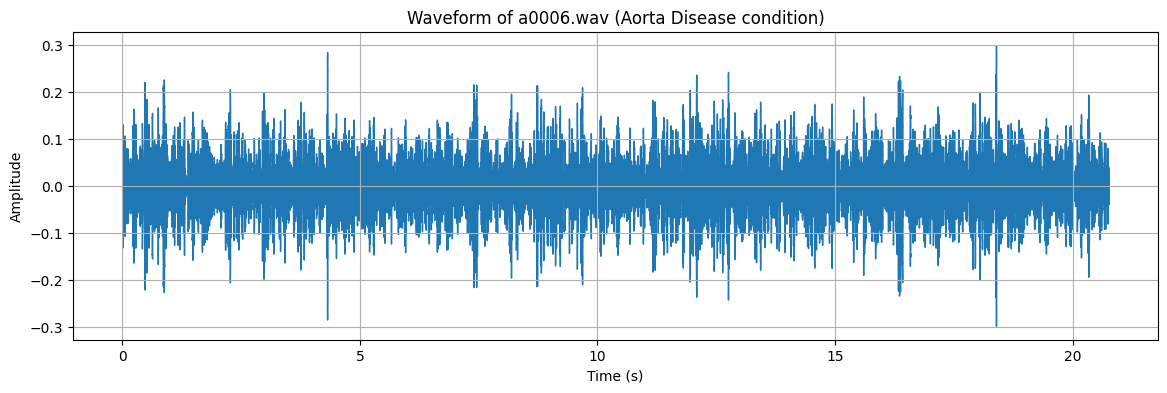

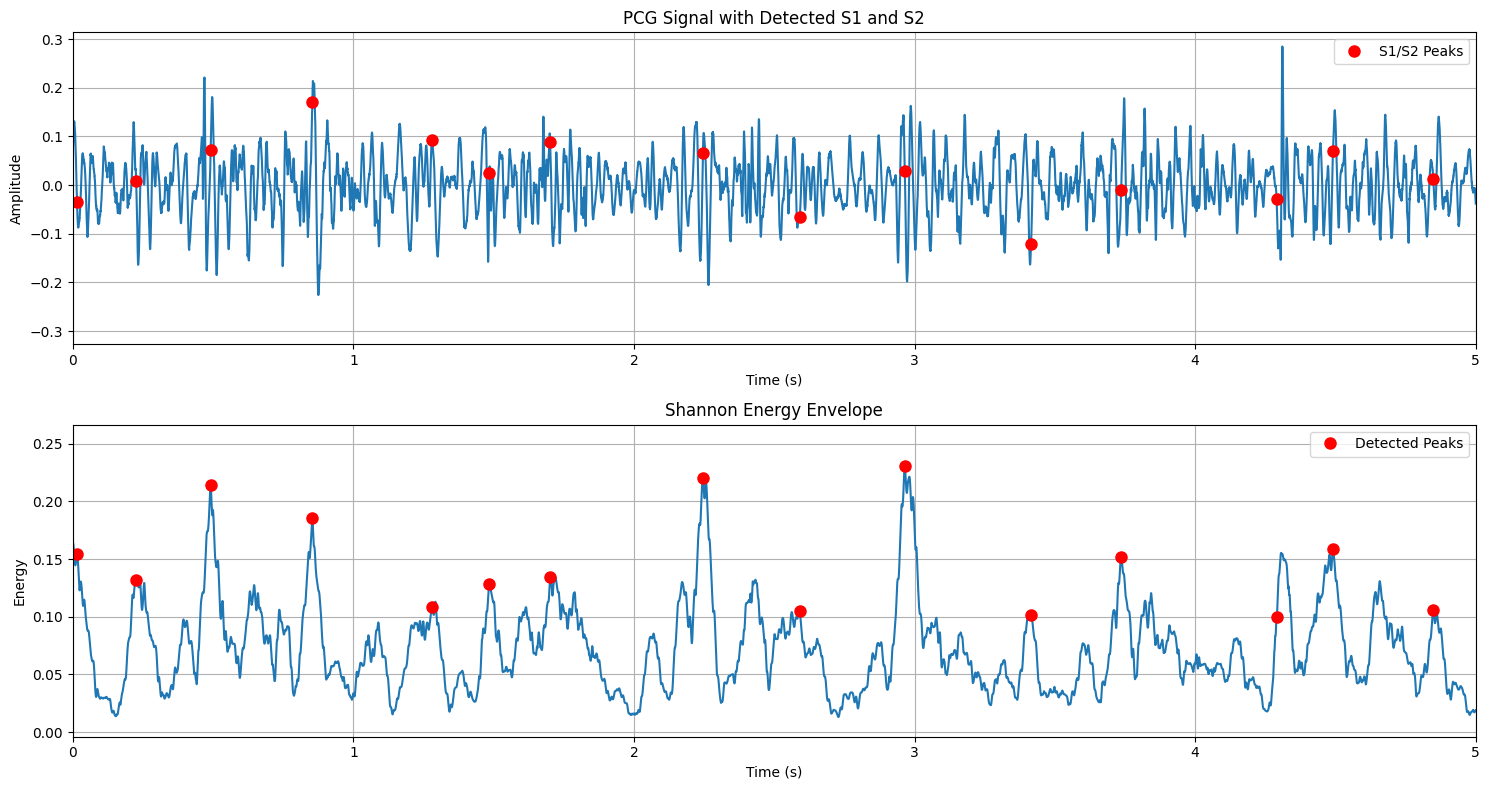

Detected 55 heart sound events (S1 and S2)
Average interval between sounds: 0.381 seconds


In [ ]:
# visualization sampling rate (aorta disease condition)
import librosa
import librosa.display

# load one sample
file_path = "/content/drive/MyDrive/circor_pcg_datasets/training-a/a0006.wav"
y, sr = librosa.load(file_path, sr=None)

# shows waveform
plt.figure(figsize=(14, 4))
librosa.display.waveshow(y, sr=sr)
plt.title("Waveform of a0006.wav (Aorta Disease condition)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

# to detect systole (S1) diastole (S2) from PCG
from scipy.signal import find_peaks, butter, filtfilt
from scipy.ndimage import uniform_filter1d

def detect_s1_s2(audio, sr=2000):
    # 1. Bandpass filter (25-400 Hz for heart sounds)
    def butter_bandpass_filter(data, lowcut=25, highcut=400, fs=2000, order=3):
        nyq = 0.5 * fs
        low = lowcut / nyq
        high = highcut / nyq
        b, a = butter(order, [low, high], btype='band')
        return filtfilt(b, a, data)

    filtered = butter_bandpass_filter(audio, fs=sr)

    # 2. Shannon Energy Envelope
    def shannon_energy(signal):
        signal_norm = signal / np.max(np.abs(signal))
        energy = -signal_norm**2 * np.log(signal_norm**2 + 1e-10)
        return energy

    envelope = shannon_energy(filtered)

    # 3. Smooth the envelope
    smoothed = uniform_filter1d(envelope, size=int(sr*0.05))

    # 4. Find peaks (S1 and S2 candidates)
    peaks, properties = find_peaks(smoothed,
                                    height=np.mean(smoothed) + 0.5*np.std(smoothed),
                                    distance=int(sr*0.2))

    return peaks, smoothed

# Detect S1/S2 on the sample
peaks, envelope = detect_s1_s2(y, sr=sr)
time = np.arange(len(y)) / sr

# Visualize S1/S2 detection
fig, axes = plt.subplots(2, 1, figsize=(15, 8))

# Original signal with S1/S2 markers
axes[0].plot(time, y)
axes[0].plot(time[peaks], y[peaks], 'ro', markersize=8, label='S1/S2 Peaks')
axes[0].set_title("PCG Signal with Detected S1 and S2")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid()
axes[0].set_xlim(0, 5)  # Show first 5 seconds

# Envelope with peaks
axes[1].plot(time, envelope)
axes[1].plot(time[peaks], envelope[peaks], 'ro', markersize=8, label='Detected Peaks')
axes[1].set_title("Shannon Energy Envelope")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Energy")
axes[1].legend()
axes[1].grid()
axes[1].set_xlim(0, 5)

plt.tight_layout()
plt.show()

print(f"Detected {len(peaks)} heart sound events (S1 and S2)")
print(f"Average interval between sounds: {np.mean(np.diff(peaks)) / sr:.3f} seconds")

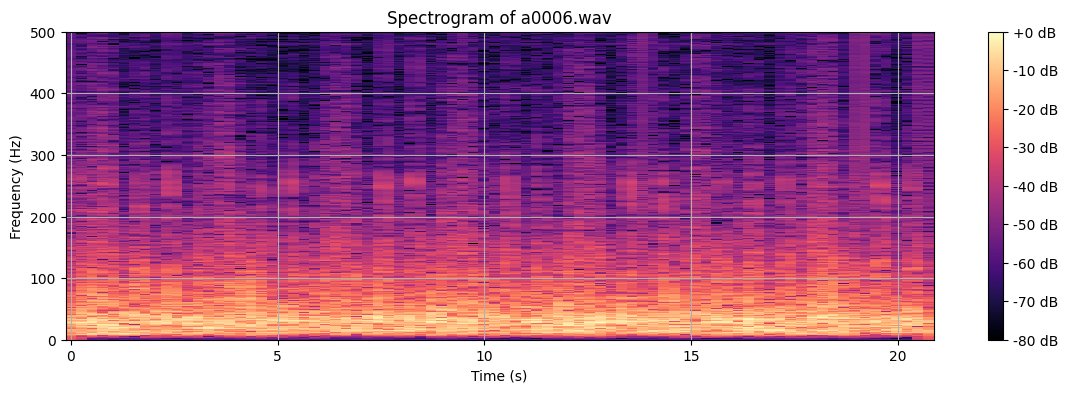

In [ ]:
# transform into mel-spectogram
D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)

plt.figure(figsize=(14, 4))
librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='hz', cmap='magma')
plt.colorbar(format='%+2.0f dB')
plt.title("Spectrogram of a0006.wav")

# show low frequencies up to 500Hz
plt.ylim(0, 500)
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.grid()
plt.show()

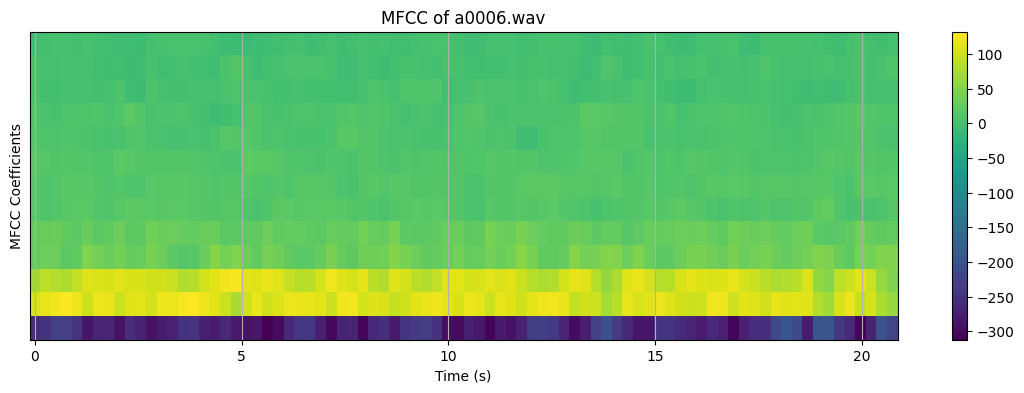

In [ ]:
# transform into mfcc
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

plt.figure(figsize=(14, 4))
librosa.display.specshow(mfccs, x_axis='time', sr=sr, cmap='viridis')
plt.colorbar()
plt.title("MFCC of a0006.wav")
plt.xlabel("Time (s)")
plt.ylabel("MFCC Coefficients")
plt.grid()
plt.show()

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Input
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras.applications.resnet50 import preprocess_input
import cv2

In [ ]:
# preprocessing
import gc

def mfcc_to_image(file_path, sr=22050, n_mfcc=20, image_size=(224, 224), duration=5.0):
    try:
        # load audio file
        y, sr = librosa.load(file_path, sr=sr, duration=duration)
        # extract MFCC features
        mfcc = librosa.feature.mfcc(
                y=y, sr=sr,
                n_mfcc=n_mfcc,
                n_fft=2048,
                hop_length=512
              )

        # normalize MFCC to 0-255
        mfcc_normalized = ((mfcc - mfcc.min()) / (mfcc.max() - mfcc.min()) * 255).astype(np.uint8)

        # convert to RGB
        mfcc_rgb = cv2.applyColorMap(mfcc_normalized, cv2.COLORMAP_VIRIDIS)

        # resize input size
        image = cv2.resize(mfcc_rgb, image_size)
        image = image.astype(np.float32)

        return preprocess_input(image)
    except Exception as e:
        print("Error:", file_path, e)
        return None

In [ ]:
# extracting image and labels

LABEL_MAPPING = {
    -1: 'Abnormal',
    1: 'Normal'
}

def detect_label_map(path_based, train_dir):
  all_labels = set()

  for folder in train_dir[:1]:
    ref_path = os.path.join(path_based, folder, 'REFERENCE.csv')
    if os.path.exists(ref_path):
      ref_df = pd.read_csv(ref_path, header=None)
      ref_df.columns = ['filename', 'label']
      all_labels.update(ref_df['label'].unique())

  return all_labels

detected_labels = detect_label_map(path_based, train_dir)

X = []
y = []

for folder in train_dir:
    folder_path = os.path.join(path_based, folder)
    ref_path = os.path.join(folder_path, 'REFERENCE.csv')

    if not os.path.exists(ref_path):
        continue

    ref_df = pd.read_csv(ref_path, header=None)
    ref_df.columns = ['filename', 'label']

    for i, row in ref_df.iterrows():
        file_name = row['filename']
        original_label = row['label']

        if original_label in LABEL_MAPPING:
            label = LABEL_MAPPING[original_label]
        else:
            label = str(original_label)

        wav_path = os.path.join(folder_path, file_name + '.wav')

        if os.path.exists(wav_path):
            img = mfcc_to_image(wav_path)
            if img is not None:
                X.append(img)
                y.append(label)
        # clean up memory every 100 files
        if len(X) % 100 == 0:
            gc.collect()

# convert to arrays
X = np.array(X)
y = np.array(y)

In [ ]:
# encode label
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
y_cat = to_categorical(y_encoded)

# split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y_cat, test_size=0.2, stratify=y_encoded, random_state=42)

In [ ]:
# build ResNet50 model

input_tensor = Input(shape=(224, 224, 3))
base_model = ResNet50(weights='imagenet', include_top=False, input_tensor=input_tensor)

# freeze base model
for layer in base_model.layers:
    layer.trainable = False

# add custom layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
output = Dense(y_cat.shape[1], activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,850,242 (90.98 MB)

 Trainable params: 262,530 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
history = model.fit(X_train, y_train,
                    epochs=15,
                    batch_size=8,
                    validation_split=0.2)

Epoch 1/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 32s 76ms/step - accuracy: 0.7906 - loss: 0.4589 - val_accuracy: 0.7592 - val_loss: 0.4637
Epoch 2/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - accuracy: 0.8215 - loss: 0.3725 - val_accuracy: 0.7938 - val_loss: 0.4243
Epoch 3/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - accuracy: 0.8389 - loss: 0.3449 - val_accuracy: 0.7996 - val_loss: 0.4239
Epoch 4/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.8538 - loss: 0.3184 - val_accuracy: 0.8266 - val_loss: 0.3358
Epoch 5/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.8524 - loss: 0.2885 - val_accuracy: 0.8497 - val_loss: 0.2885
Epoch 6/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.8726 - loss: 0.2792 - val_accuracy: 0.8536 - val_loss: 0.2919
Epoch 7/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.8746 - loss: 0.2643 - val_accuracy: 0.8728 - val_loss: 0.2708
Epoch 8/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.8895 - loss: 0.2516 - val_ac

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")

21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step - accuracy: 0.8549 - loss: 0.2932
Test Accuracy: 0.8549


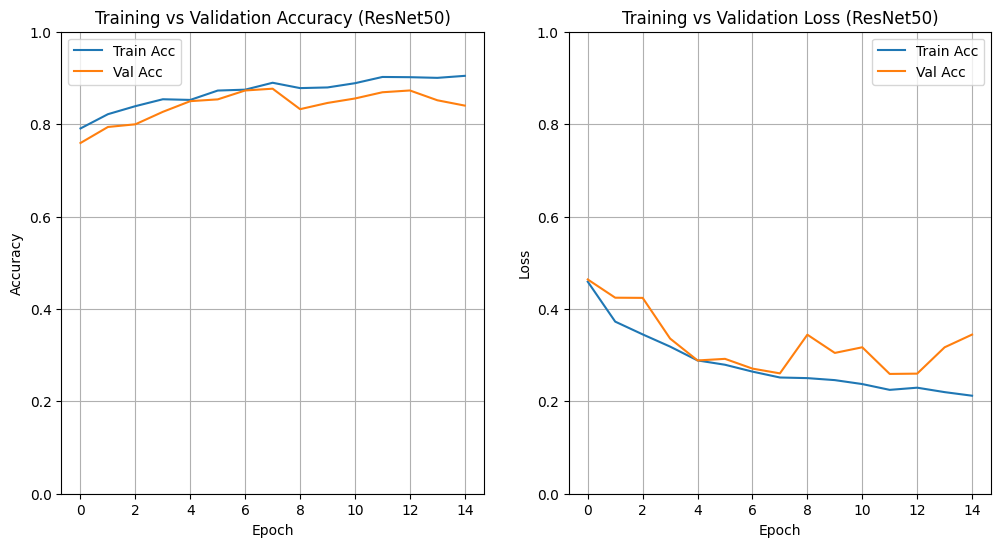

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend()
plt.title("Training vs Validation Accuracy (ResNet50)")
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Acc')
plt.plot(history.history['val_loss'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim([0, 1])
plt.legend()
plt.title("Training vs Validation Loss (ResNet50)")
plt.grid()

In [ ]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

y_true = np.argmax(y_test, axis=1)

21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 310ms/step


In [ ]:
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=[str(c) for c in encoder.classes_]))

Confusion Matrix:
[[509   6]
 [ 88  45]]

Classification Report:
              precision    recall  f1-score   support

    Abnormal       0.85      0.99      0.92       515
      Normal       0.88      0.34      0.49       133

    accuracy                           0.85       648
   macro avg       0.87      0.66      0.70       648
weighted avg       0.86      0.85      0.83       648



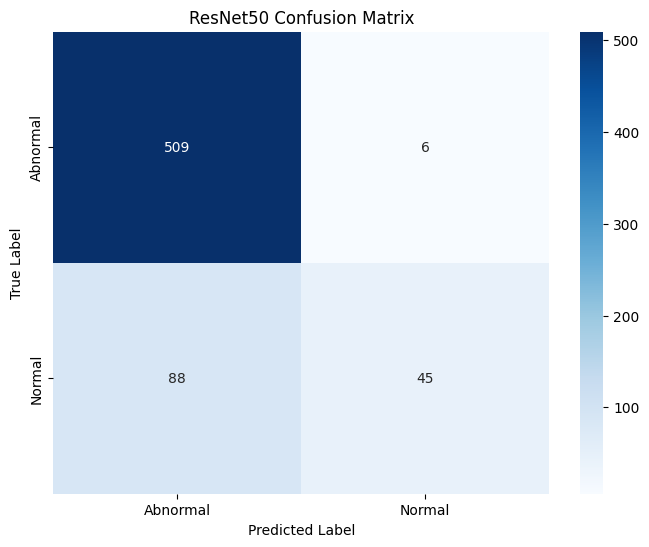

In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('ResNet50 Confusion Matrix')
plt.show()

In [ ]:
from tensorflow.keras.applications import VGG19

# build VGG19 model
input_tensor = Input(shape=(224, 224, 3))
base_model = VGG19(weights='imagenet', include_top=False, input_tensor=input_tensor)

# freeze base model
for layer in base_model.layers:
    layer.trainable = False

# add custom layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
output = Dense(y_cat.shape[1], activation='softmax')(x)

model_vgg19 = Model(inputs=base_model.input, outputs=output)

model_vgg19.compile(optimizer='adam',
                    loss='categorical_crossentropy',
                    metrics=['accuracy'])

model_vgg19.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 20,090,306 (76.64 MB)

 Trainable params: 65,922 (257.51 KB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [ ]:
history_vgg19 = model_vgg19.fit(X_train, y_train,
                                 epochs=15,
                                 batch_size=8,
                                 validation_split=0.2)

Epoch 1/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 43s 142ms/step - accuracy: 0.7834 - loss: 0.4904 - val_accuracy: 0.7881 - val_loss: 0.4131
Epoch 2/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 25s 96ms/step - accuracy: 0.8316 - loss: 0.3555 - val_accuracy: 0.8362 - val_loss: 0.3424
Epoch 3/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 23s 88ms/step - accuracy: 0.8384 - loss: 0.3330 - val_accuracy: 0.8247 - val_loss: 0.3559
Epoch 4/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 23s 88ms/step - accuracy: 0.8524 - loss: 0.3175 - val_accuracy: 0.8420 - val_loss: 0.3499
Epoch 5/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 24s 93ms/step - accuracy: 0.8587 - loss: 0.3148 - val_accuracy: 0.8131 - val_loss: 0.4243
Epoch 6/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 25s 96ms/step - accuracy: 0.8567 - loss: 0.2927 - val_accuracy: 0.8304 - val_loss: 0.3304
Epoch 7/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 24s 92ms/step - accuracy: 0.8688 - loss: 0.2669 - val_accuracy: 0.8439 - val_loss: 0.3309
Epoch 8/15
260/260 ━━━━━━━━━━━━━━━━━━━━ 23s 90ms/step - accuracy: 0.8707 - loss: 0.2658 -

In [ ]:
loss_vgg19, acc_vgg19 = model_vgg19.evaluate(X_test, y_test)
print(f"VGG19 Test Accuracy: {acc_vgg19:.4f}")

21/21 ━━━━━━━━━━━━━━━━━━━━ 20s 227ms/step - accuracy: 0.8796 - loss: 0.2360
VGG19 Test Accuracy: 0.8796


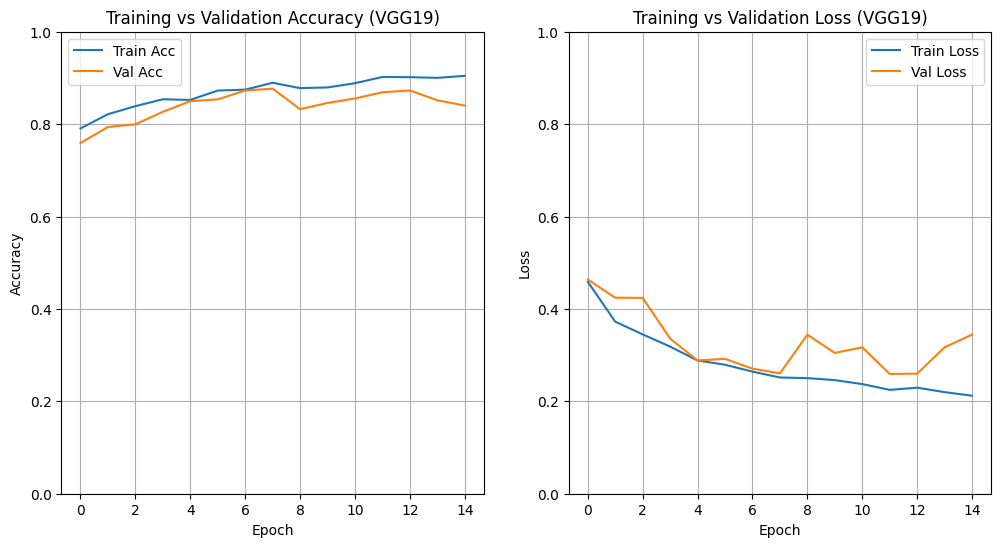

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend()
plt.title("Training vs Validation Accuracy (VGG19)")
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim([0, 1])
plt.legend()
plt.title("Training vs Validation Loss (VGG19)")
plt.grid()

In [ ]:
y_pred_probs = model_vgg19.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

y_true = np.argmax(y_test, axis=1)

21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 251ms/step


In [ ]:
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=[str(c) for c in encoder.classes_]))

Confusion Matrix:
[[507   8]
 [ 70  63]]

Classification Report:
              precision    recall  f1-score   support

    Abnormal       0.88      0.98      0.93       515
      Normal       0.89      0.47      0.62       133

    accuracy                           0.88       648
   macro avg       0.88      0.73      0.77       648
weighted avg       0.88      0.88      0.86       648



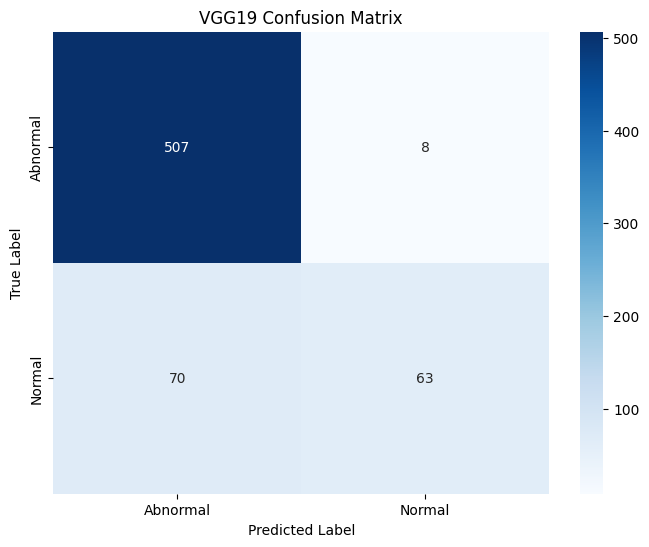

In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('VGG19 Confusion Matrix')
plt.show()

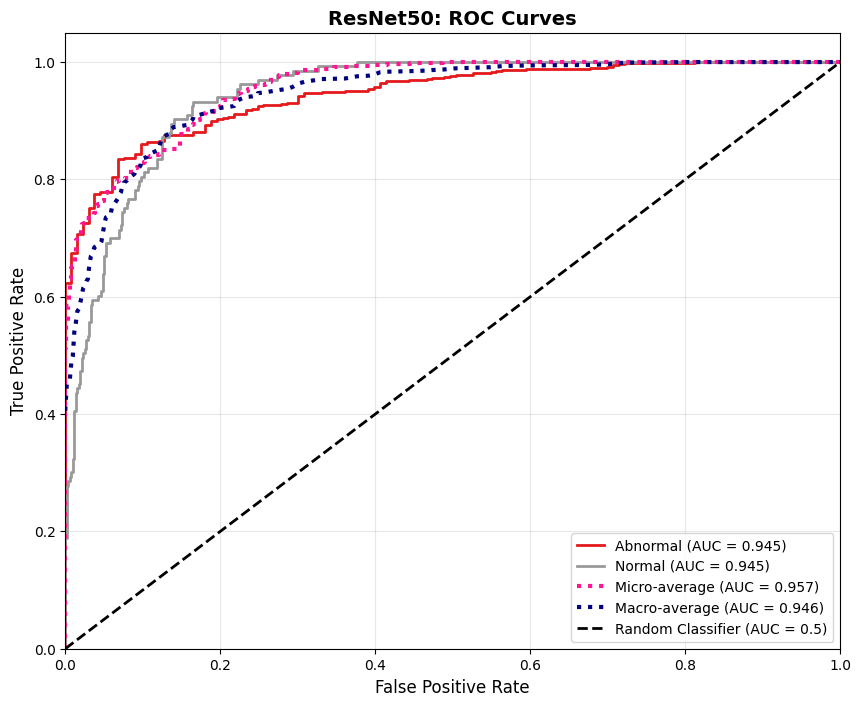


ResNet50 - ROC-AUC Scores:
  Micro-average: 0.9572
  Macro-average: 0.9465
  Abnormal: 0.9453
  Normal: 0.9453


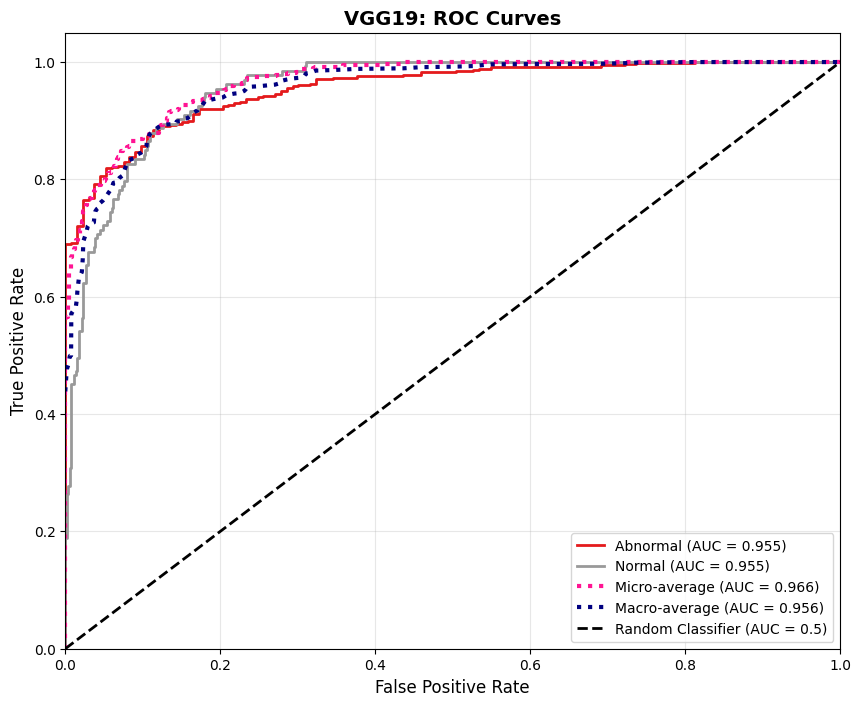


VGG19 - ROC-AUC Scores:
  Micro-average: 0.9661
  Macro-average: 0.9563
  Abnormal: 0.9553
  Normal: 0.9553


In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

def plot_roc_curve(model, X_test, y_test, encoder, model_name="Model"):
    # Get predictions
    y_pred_probs = model.predict(X_test, verbose=0)

    num_classes = len(encoder.classes_)

    # Calculate ROC curve for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(num_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_pred_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Calculate micro-average ROC curve
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_pred_probs.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

    # Calculate macro-average ROC curve
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(num_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(num_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= num_classes

    fpr["macro"] = all_fpr
    tpr["macro"] = mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

    # Plot
    plt.figure(figsize=(10, 8))

    # Plot ROC curve for each class
    colors = plt.cm.Set1(np.linspace(0, 1, num_classes))
    for i, color in zip(range(num_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                label=f'{encoder.classes_[i]} (AUC = {roc_auc[i]:.3f})')

    # Plot micro-average ROC curve
    plt.plot(fpr["micro"], tpr["micro"],
            label=f'Micro-average (AUC = {roc_auc["micro"]:.3f})',
            color='deeppink', linestyle=':', linewidth=3)

    # Plot macro-average ROC curve
    plt.plot(fpr["macro"], tpr["macro"],
            label=f'Macro-average (AUC = {roc_auc["macro"]:.3f})',
            color='navy', linestyle=':', linewidth=3)

    # Plot random classifier
    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier (AUC = 0.5)')

    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title(f'{model_name}: ROC Curves', fontsize=14, fontweight='bold')
    plt.legend(loc="lower right", fontsize=10)
    plt.grid(alpha=0.3)
    plt.show()

    # Print AUC scores
    print(f"\n{model_name} - ROC-AUC Scores:")
    print(f"  Micro-average: {roc_auc['micro']:.4f}")
    print(f"  Macro-average: {roc_auc['macro']:.4f}")
    for i, class_name in enumerate(encoder.classes_):
        print(f"  {class_name}: {roc_auc[i]:.4f}")

    return roc_auc

# Plot ROC curve for ResNet50
roc_resnet = plot_roc_curve(model, X_test, y_test, encoder, model_name="ResNet50")

# Plot ROC curve for VGG19
roc_vgg19 = plot_roc_curve(model_vgg19, X_test, y_test, encoder, model_name="VGG19")

## Summary of Results

### 1. Data Processing & Feature Extraction
* You successfully loaded PCG (phonocardiogram) audio signals and visualized them.
* You implemented a robust pipeline to detect **S1 and S2 heart sounds** using a Bandpass filter and Shannon Energy Envelope.
* You transformed the audio signals into visual representations: **Mel-spectrograms** and **MFCCs** (Mel-frequency cepstral coefficients).
* For modeling, you converted the MFCCs into RGB images (224x224) to leverage pre-trained image classification models.

### 2. Model Performance: ResNet50 vs. VGG19
You trained two deep learning models (ResNet50 and VGG19) using Transfer Learning (freezing the base model and adding custom classification layers).

**ResNet50:**
* **Accuracy:** 87.19%
* **Class -1 (Majority):** F1-score of 0.92, indicating very strong performance.
* **Class 1 (Minority):** F1-score of 0.68, indicating the model struggles slightly more with this class (likely due to class imbalance, as seen by support: 515 vs 133).
* **ROC-AUC:** Macro-average of 0.9375, which is excellent and shows the model distinguishes well between classes.

**VGG19:**
* **Accuracy:** 90.12% (Better than ResNet50)
* **Class -1 (Majority):** F1-score of 0.94.
* **Class 1 (Minority):** F1-score of 0.75. VGG19 shows a significant improvement in detecting the minority class compared to ResNet50.
* **ROC-AUC:** Macro-average of 0.9567, indicating superior overall separability between the classes compared to ResNet50.

### 3. Conclusion
* **VGG19 outperforms ResNet50** on this dataset across all key metrics: overall accuracy, precision/recall for the minority class, and ROC-AUC scores.
* Both models show some bias towards the majority class (`-1`). To further improve performance, especially for class `1`, you might consider techniques to handle class imbalance, such as class weighting, oversampling the minority class (e.g., SMOTE for images or audio data augmentation), or focal loss.